# Mineral intensity — LCI output

The combined mineral-intensity table produced by the LCI pipeline
(`build/lci/mineral_intensity_combined.csv`, see `scripts/standardise.py` and
`scripts/combine_sources.py`). Each row is one technology (`sub_technology`); each
mineral column is the amount of that raw material embodied **per functional unit**
(the unit varies per row — see the `unit` column).

Every row is a computed inventory. What differs is where the foreground came from:
the prospective *premise* database's own datasets, the one present-day *ecoinvent*
dataset, the transcribed *bill of materials* turned into activities over premise
(wind, solar, electrolysers), and the two *derived* foregrounds (the aluminium
conductors and the induction motor).

Run by the `visualise_lci` rule, or interactively (paths then resolve relative to
the repo root).

## Vintage

The background is premise at `lci.premise_scenario.year` (2030). The foregrounds are not all of that year. *Source* gives the publication year in brackets; *data year* is the year the foreground's quantities represent.

| Sub-technologies | Foreground source | Data year | Background |
|---|---|---|---|
| PV (bill of materials) | Carrara et al. (2020), Table 4, MDS | 2030 (projected) | 2030 |
| Wind (bill of materials) | Carrara et al. (2020), Table 2 | 2018 | 2030 |
| Electrolysers (bill of materials) | Gerloff (2021) | ~2019–20 | 2030 |
| Li-ion batteries bar NMC532 | Dai et al. (2019) via Crenna et al. (2021), in premise | 2020 cells, scaled to 2030 energy density | 2030 |
| Battery, Na-ion | Zhang et al. (2024), in premise | 2020 cells, scaled to 2030 energy density | 2030 |
| Battery, NMC532 | Dai et al. (2019) via Crenna et al. (2021), in premise | 2020, unscaled | 2030 |
| Nuclear | premise metals database (2.3.0) over ecoinvent 3.10's PWR | 2020 materials; plant from 1979 | 2030 |
| Gas plants | ecoinvent 3.10 | 1990 | 2030 |
| Heat pump | ecoinvent 3.10 | 1990 | 2030 |
| Grid and its Al variants | ecoinvent 3.10, from Itten et al. (2014) | HV AC and HVDC 1998, MV 1988, LV 2008 | 2030 |
| EV motor, PM | ecoinvent 3.10 | 2005; magnet 1995 | ecoinvent 3.10 |
| EV motor, induction | EV motor, PM, with Cu ×2.43 and magnet REEs ×0 from Månberger & Stenqvist (2018) | as EV motor, PM | ecoinvent 3.10 |

An ecoinvent data year is the start of the dataset's time period, which ecoinvent 3.10 runs to 2023 for every dataset here. premise scales the battery markets' kg of battery per kWh by energy density at the background year. Wind and the electrolysers stay at their measured year, as neither source has 2030 values. The EV motors stay on plain ecoinvent because premise's magnet dataset carries 1.6 ppm Nd₂O₃.

In [1]:
import sys
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above
from info_schemas import ConductorComparison, Intensity  # noqa: E402

try:
    paths = {
        "intensity": snakemake.input.intensity,  # noqa: F821 — injected by the snakemake notebook rule
        "conductors": snakemake.input.conductors,  # noqa: F821
        "figures": snakemake.output.figures,  # noqa: F821
    }
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        style = yaml.safe_load(f)["plotting"]
    paths = {
        "intensity": repo / "build/lci/mineral_intensity_combined.csv",
        "conductors": repo / "build/lci/conductor_substitution_effect.csv",
        "figures": repo / "build/lci/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]

In [2]:
df = pd.read_csv(paths["intensity"])

# Everything the intensity schema doesn't claim as metadata is a mineral amount
# (synthetic graphite included), so the table itself defines what there is to plot.
value_columns = [c for c in df.columns if c not in set(Intensity)]

# sub_technology is the per-row label — unique across the combined table.
df["label"] = df[Intensity.sub_technology]
df

,sub_technology,unit,database,Aluminium,Cadmium,Cobalt,Copper,Dysprosium,Gallium,Germanium,...,Niobium,Platinum,Praseodymium,Selenium,Silver,Tellurium,Terbium,Tin,Vanadium,label
0,"Grid line, LV",km,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,205.070646,0.000344,0.185655,3767.296212,0.000801,4.826687e-03,0.000497,...,0.011185,0.000240,0.006468,0.000047,0.065769,0.000299,0.000212,1.356121,0.025133,"Grid line, LV"
1,"Grid line, LV (Al)",km,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030-alumin...,1924.010256,0.000255,0.154221,59.237473,0.000705,4.995470e-03,0.000424,...,0.009882,0.000186,0.004145,0.000040,0.057226,0.000236,0.000190,1.145369,0.020597,"Grid line, LV (Al)"
2,"Gas power plant, OC",MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,562.839069,0.000218,0.140944,616.915884,0.000431,3.334807e-03,0.000252,...,0.007003,0.000184,0.001595,0.000028,0.035322,0.000192,0.000109,0.703556,0.014261,"Gas power plant, OC"
3,"Gas power plant, CC",MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,913.458691,0.000707,2.227298,922.650996,0.001206,9.344217e-03,0.000707,...,0.019646,0.000533,0.003749,0.000080,0.099228,0.000626,0.000304,1.966123,0.039151,"Gas power plant, CC"
4,Heat pump,MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,60.177441,0.000453,0.172422,1788.907511,0.000578,5.206067e-03,0.000262,...,0.010929,0.000146,0.033735,0.000047,0.040328,0.000403,0.000156,0.789582,0.025619,Heat pump
5,"Battery, LFP",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1592.274631,0.000791,0.201871,806.653784,0.001208,9.999258e-03,0.000570,...,0.019868,0.000280,0.102027,0.000090,0.748220,0.000712,0.000349,8.083082,0.046230,"Battery, LFP"
6,"Battery, LFP, stationary",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1592.274631,0.000791,0.201871,806.653784,0.001208,9.999258e-03,0.000570,...,0.019868,0.000280,0.102027,0.000090,0.748220,0.000712,0.000349,8.083082,0.046230,"Battery, LFP, stationary"
7,"Battery, NCA",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,998.597656,0.000783,106.413558,693.095021,0.001111,8.013132e-03,0.000515,...,0.017752,0.000272,0.044440,0.000073,0.557322,0.000652,0.000328,6.381169,0.038011,"Battery, NCA"
8,"Battery, NMC111",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1484.221489,0.001176,408.094554,1281.309243,0.001746,1.259010e-02,0.000800,...,0.026653,0.000421,0.071859,0.000115,0.822148,0.001023,0.000531,9.369184,0.058606,"Battery, NMC111"
9,"Battery, NMC111, stationary",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1484.221489,0.001176,408.094554,1281.309243,0.001746,1.259010e-02,0.000800,...,0.026653,0.000421,0.071859,0.000115,0.822148,0.001023,0.000531,9.369184,0.058606,"Battery, NMC111, stationary"


In [3]:
# Single-hue sequential ramp (magnitude), recessive axes — matches the house style.
SEQUENTIAL = "viridis"
SOURCE_COLORS = {
    "premise": "#2a78d6",
    "ecoinvent": "#33a02c",
    "bill of materials": "#eda100",
    "derived": "#9467bd",
}
SOURCE_NAMES = {source: source for source in SOURCE_COLORS}


def source_of(database):
    """Where a row's foreground came from, read off its `database` tag.

    The derived foregrounds carry the database they resolve into plus a suffix, so
    the suffixes are tested before the prefixes.
    """
    d = str(database)
    if d.endswith("-bill-of-materials"):
        return "bill of materials"
    if d.endswith(("-aluminium-conductor", "-motor-substitution")):
        return "derived"
    if d.startswith("ei_"):
        return "premise"
    if d.startswith("ecoinvent"):
        return "ecoinvent"
    raise ValueError(f"unrecognised database tag {database!r}")


df["source"] = df[Intensity.database].map(source_of)

## Coverage

Which (technology, mineral) pairs carry a non-zero intensity. Empty cells are
structurally absent, not missing data.

In [4]:
df

,sub_technology,unit,database,Aluminium,Cadmium,Cobalt,Copper,Dysprosium,Gallium,Germanium,...,Platinum,Praseodymium,Selenium,Silver,Tellurium,Terbium,Tin,Vanadium,label,source
0,"Grid line, LV",km,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,205.070646,0.000344,0.185655,3767.296212,0.000801,4.826687e-03,0.000497,...,0.000240,0.006468,0.000047,0.065769,0.000299,0.000212,1.356121,0.025133,"Grid line, LV",premise
1,"Grid line, LV (Al)",km,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030-alumin...,1924.010256,0.000255,0.154221,59.237473,0.000705,4.995470e-03,0.000424,...,0.000186,0.004145,0.000040,0.057226,0.000236,0.000190,1.145369,0.020597,"Grid line, LV (Al)",derived
2,"Gas power plant, OC",MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,562.839069,0.000218,0.140944,616.915884,0.000431,3.334807e-03,0.000252,...,0.000184,0.001595,0.000028,0.035322,0.000192,0.000109,0.703556,0.014261,"Gas power plant, OC",premise
3,"Gas power plant, CC",MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,913.458691,0.000707,2.227298,922.650996,0.001206,9.344217e-03,0.000707,...,0.000533,0.003749,0.000080,0.099228,0.000626,0.000304,1.966123,0.039151,"Gas power plant, CC",premise
4,Heat pump,MW,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,60.177441,0.000453,0.172422,1788.907511,0.000578,5.206067e-03,0.000262,...,0.000146,0.033735,0.000047,0.040328,0.000403,0.000156,0.789582,0.025619,Heat pump,premise
5,"Battery, LFP",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1592.274631,0.000791,0.201871,806.653784,0.001208,9.999258e-03,0.000570,...,0.000280,0.102027,0.000090,0.748220,0.000712,0.000349,8.083082,0.046230,"Battery, LFP",premise
6,"Battery, LFP, stationary",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1592.274631,0.000791,0.201871,806.653784,0.001208,9.999258e-03,0.000570,...,0.000280,0.102027,0.000090,0.748220,0.000712,0.000349,8.083082,0.046230,"Battery, LFP, stationary",premise
7,"Battery, NCA",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,998.597656,0.000783,106.413558,693.095021,0.001111,8.013132e-03,0.000515,...,0.000272,0.044440,0.000073,0.557322,0.000652,0.000328,6.381169,0.038011,"Battery, NCA",premise
8,"Battery, NMC111",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1484.221489,0.001176,408.094554,1281.309243,0.001746,1.259010e-02,0.000800,...,0.000421,0.071859,0.000115,0.822148,0.001023,0.000531,9.369184,0.058606,"Battery, NMC111",premise
9,"Battery, NMC111, stationary",MWh,ei_cutoff_3.10_tiam-ucl_SSP2-RCP19_2030,1484.221489,0.001176,408.094554,1281.309243,0.001746,1.259010e-02,0.000800,...,0.000421,0.071859,0.000115,0.822148,0.001023,0.000531,9.369184,0.058606,"Battery, NMC111, stationary",premise


In [5]:
coverage = df.set_index("label")[value_columns] > 0
coverage = coverage.loc[:, coverage.any()]  # drop minerals no technology uses
coverage.replace({True: "x", False: ""})

,Aluminium,Cadmium,Cobalt,Copper,Dysprosium,Gallium,Germanium,Graphite,Indium,Iridium,...,Nickel,Niobium,Platinum,Praseodymium,Selenium,Silver,Tellurium,Terbium,Tin,Vanadium
label,,,,,,,,,,,,,,,,,,,,,
"Grid line, LV",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Grid line, LV (Al)",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Gas power plant, OC",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Gas power plant, CC",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
Heat pump,x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Battery, LFP",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Battery, LFP, stationary",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Battery, NCA",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x
"Battery, NMC111",x,x,x,x,x,x,x,x,x,x,...,x,x,x,x,x,x,x,x,x,x


## Intensity heatmap

Mineral intensity per functional unit across every technology. Values span many
orders of magnitude, so the colour scale is **log10**; blank cells are zero / absent.

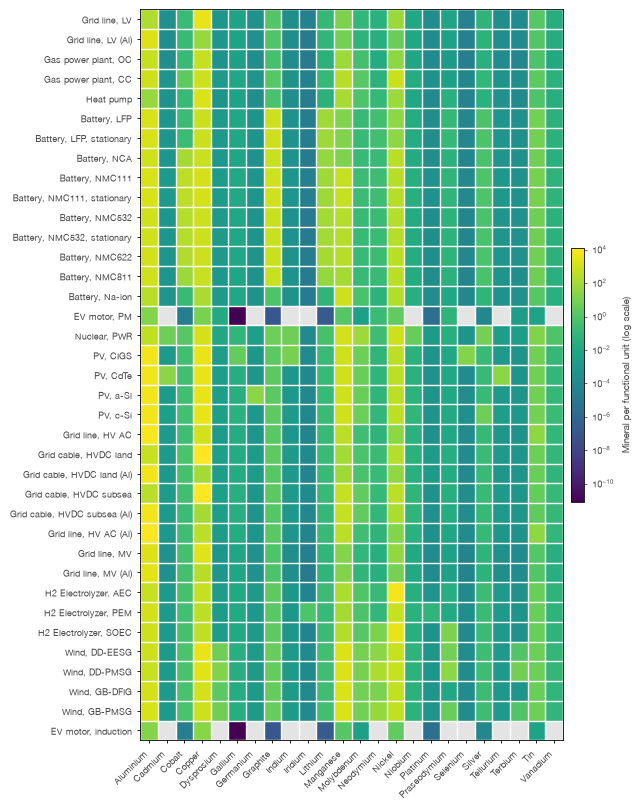

In [6]:
used_minerals = [m for m in value_columns if (df[m] > 0).any()]
matrix = df.set_index("label")[used_minerals]
masked = np.ma.masked_where(matrix.values <= 0, matrix.values)

# A row per technology, and the chrome twice over: the slanted mineral names
# under the panel take about what the colour bar takes above it.
fig, (ax,) = plotting.page_figure(
    style,
    height=plotting.bar_panel_height(len(matrix), style)
    + style["supplement"]["panel_chrome"],
)
cmap = plt.get_cmap(SEQUENTIAL).copy()
cmap.set_bad(ink["grid"])  # zero / absent
im = ax.imshow(
    masked,
    aspect="auto",
    cmap=cmap,
    norm=mcolors.LogNorm(vmin=np.nanmin(masked), vmax=np.nanmax(masked)),
)
ax.set_xticks(range(len(used_minerals)), used_minerals, rotation=45, ha="right",
              color=ink["secondary"])
ax.set_yticks(range(len(matrix)), matrix.index, color=ink["secondary"])
ax.set_xticks(np.arange(-0.5, len(used_minerals), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(matrix), 1), minor=True)
# A hairline of surface between cells, the same separator the stacked bars use.
ax.grid(which="minor", color=style["bar"]["edge_color"], linewidth=1.0)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
cbar = fig.colorbar(im, ax=ax, pad=0.02, fraction=0.03)
cbar.set_label("Mineral per functional unit (log scale)", color=ink["secondary"])
cbar.ax.tick_params(colors=ink["secondary"])
plotting.save_figure(fig, figures_dir, "intensity_heatmap", style)

## Which technologies drive each mineral

For every mineral in use, the technologies ranked by intensity (log x-axis). Bars
coloured by where the foreground came from. Each bar is per its own technology's
functional unit, given in brackets after its name.

In [ ]:
TOP_N = 12  # bars a ranking panel carries
ranking = style["lci_ranking"]
unit_names = ranking["unit_names"]


def top_technologies(mineral, n=TOP_N):
    s = df[df[mineral] > 0][["label", Intensity.unit, "source", mineral]].nlargest(
        n, mineral
    )
    return s.iloc[::-1]  # largest at top


for page, (fig, axes, page_minerals) in enumerate(
    plotting.paged_grid(
        used_minerals, style, max_columns=ranking["columns"], rows=ranking["rows"]
    ),
    start=1,
):
    for ax, mineral in zip(axes, page_minerals):
        top = top_technologies(mineral)
        names = [
            f"{label} [{unit_names[unit]}]"
            for label, unit in zip(top["label"], top[Intensity.unit])
        ]
        ax.barh(names, top[mineral], color=top["source"].map(SOURCE_COLORS),
                height=0.7)
        plotting.style_panel(
            ax, style, title=mineral, ylabel="kg per functional unit", log=True,
            orientation="horizontal", title_loc="center", label_loc="right",
        )
        plotting.decade_axis(ax, top[mineral], orientation="horizontal")
    legend = fig.legend(
        handles=plotting.patch_handles(SOURCE_COLORS, SOURCE_COLORS, SOURCE_NAMES),
        loc="outside lower center", frameon=False, ncol=len(SOURCE_COLORS),
    )
    plotting.save_figure(
        fig, figures_dir, f"top_technologies_by_mineral_{page}", style, (legend,)
    )

## Per-technology material usage

The inverse of the previous view: for every technology, the minerals it embodies
ranked by intensity (log x-axis). Each panel is one technology, per functional unit.

In [ ]:
def top_minerals(values, n=TOP_N):
    s = values[values > 0].nlargest(n)
    return s.iloc[::-1]  # largest at top


usage = df.set_index("label")[used_minerals]  # numeric matrix, one row per technology
technologies = usage[usage.sum(axis=1) > 0]
source_by_label = df.set_index("label")["source"]
unit_by_label = df.set_index("label")[Intensity.unit]

for page, (fig, axes, page_labels) in enumerate(
    plotting.paged_grid(
        list(technologies.index),
        style,
        max_columns=ranking["columns"],
        rows=ranking["rows"],
    ),
    start=1,
):
    for ax, label in zip(axes, page_labels):
        top = top_minerals(technologies.loc[label])
        ax.barh(top.index, top.values, color=SOURCE_COLORS[source_by_label[label]],
                height=0.7)
        plotting.style_panel(
            ax, style, title=label, ylabel=f"kg per {unit_names[unit_by_label[label]]}",
            log=True, orientation="horizontal", title_loc="center", label_loc="right",
        )
        plotting.decade_axis(ax, top.values, orientation="horizontal")
    legend = fig.legend(
        handles=plotting.patch_handles(SOURCE_COLORS, SOURCE_COLORS, SOURCE_NAMES),
        loc="outside lower center", frameon=False, ncol=len(SOURCE_COLORS),
    )
    plotting.save_figure(
        fig, figures_dir, f"materials_by_technology_{page}", style, (legend,)
    )

## Graphite — what the intensity counts

Graphite reaches the inventory by two routes, and only one is counted.

- **`synthetic graphite, battery grade`** is the anode. A manufactured product has
  no biosphere flow, so `run_lci` tallies it off the LCA supply array instead of
  from an `in ground` flow, and writes it as a route of `Graphite`. Read it as
  **anode graphite, not as synthetic graphite**: the mass is set by cell chemistry,
  and natural spherical and synthetic have near enough the same specific capacity,
  so the kg/kWh is the anode's whichever route supplies it. ecoinvent happens to
  build the anode from the synthetic one.
- **`graphite`**, the mined in-ground flow, is `off_grade` in
  `data/lci_route_info.csv`. It is real material — PV, gas plants, nuclear, the
  grids, the electrolysers — but refractory and electrode flake, which the
  battery-grade supply the study tracks cannot meet and does not compete for. In the
  reference scenario it is 809 kt, 4% of graphite demand. Nine tenths of it is on PV,
  scaling with c-Si's silicon, and batteries carry it at 0.003 kg/kWh against the
  anode's 0.93.

So graphite is scoped to battery grade, matching the CRMA's own wording
(*"graphite — battery grade"*) and the supply series. **Non-battery-grade graphite
is outside the study**: the technologies above report none, which belongs in the
limitations rather than being read as an absence of material.

A natural-versus-synthetic anode scenario is **not** readable here — neither the
inventory nor the supply series resolves the split within battery grade. It would
need a foreground substitution database, the way the aluminium conductor below is
derived from its copper parent.

## Conductor substitution — aluminium against its copper parent

The five grid datasets `build_conductor_substitution_db` derives, each set against the
ecoinvent dataset it was copied from. Pairing and both intensities come from
`build/lci/conductor_substitution_effect.csv` (rule `compare_conductor_intensity`,
which reads the pairing off `data/grid_conductor_info.csv`).

The two datasets in a pair differ in exactly one thing — what the conductor is made of
— so every difference between the bars is that swap, either directly or propagated
through the shared ecoinvent background. Ten minerals per panel, the largest on either
side, log x-axis.

Each panel is scaled to its own dataset, since the five span several orders of
magnitude; compare panels on the ratio view below, not on this one.

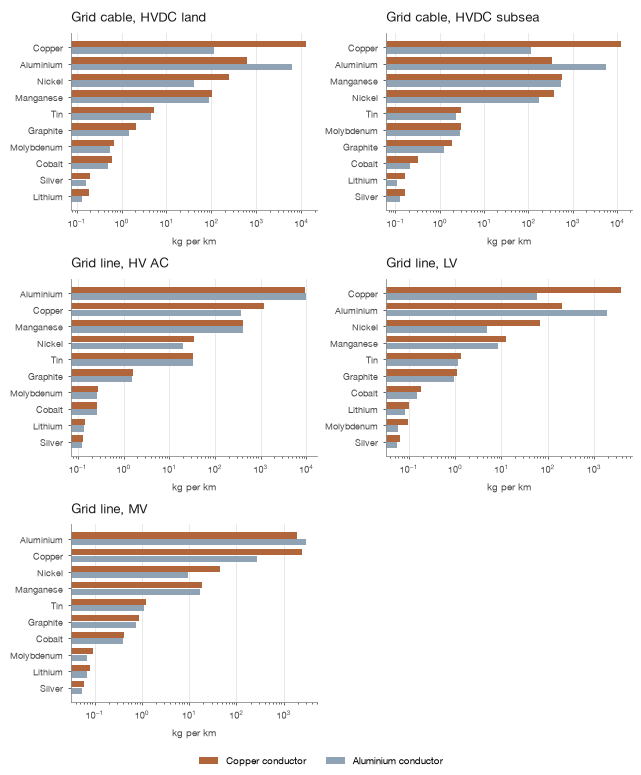

In [9]:
pairs = pd.read_csv(paths["conductors"])
copper_labels = list(pairs[ConductorComparison.copper_sub_technology].unique())

# Warm and dark against cool and light, so the pair also separates in greyscale.
CONDUCTOR_COLORS = {"copper": "#b0653a", "aluminium": "#8fa3b5"}
CONDUCTOR_NAMES = {"copper": "Copper conductor", "aluminium": "Aluminium conductor"}
PAIR_MINERALS = 10  # rows a pair panel carries, which is also what sets its height
PAIR_COLUMNS = 2  # a dataset name is too wide for three across the page


def pair_minerals(copper_label, n=PAIR_MINERALS):
    """The n minerals of one conductor pair carrying the most metal on either side.
    The rule already sorts them that way, so this only takes the top off."""
    p = pairs[pairs[ConductorComparison.copper_sub_technology] == copper_label]
    return p.head(n).iloc[::-1]  # largest at top


fig, axes = plotting.page_grid(
    len(copper_labels),
    style,
    max_columns=PAIR_COLUMNS,
    row_height=plotting.bar_panel_height(PAIR_MINERALS, style),
)
for ax, copper_label in zip(axes, copper_labels):
    p = pair_minerals(copper_label)
    y = np.arange(len(p))
    ax.barh(y + 0.2, p[ConductorComparison.copper_intensity],
            height=0.38, color=CONDUCTOR_COLORS["copper"])
    ax.barh(y - 0.2, p[ConductorComparison.aluminium_intensity],
            height=0.38, color=CONDUCTOR_COLORS["aluminium"])
    ax.set_yticks(y, p[ConductorComparison.mineral], color=ink["secondary"])
    plotting.style_panel(
        ax, style, title=copper_label, log=True, orientation="horizontal",
        ylabel=f"kg per {p[ConductorComparison.unit].iloc[0]}",
    )

legend = fig.legend(
    handles=plotting.patch_handles(
        CONDUCTOR_COLORS, CONDUCTOR_COLORS, CONDUCTOR_NAMES
    ),
    loc="outside lower center", frameon=False, ncol=2,
)
plotting.save_figure(
    fig, figures_dir, "conductor_substitution_levels", style, (legend,)
)

### What the swap multiplies each mineral by

The same comparison read as a ratio rather than a level. Log axis centred on 1: left of
the line the swap relieves the mineral, right of it the swap loads it.

A large ratio on a trace mineral is still a trace amount, so this is read alongside the
levels above, never instead of them.

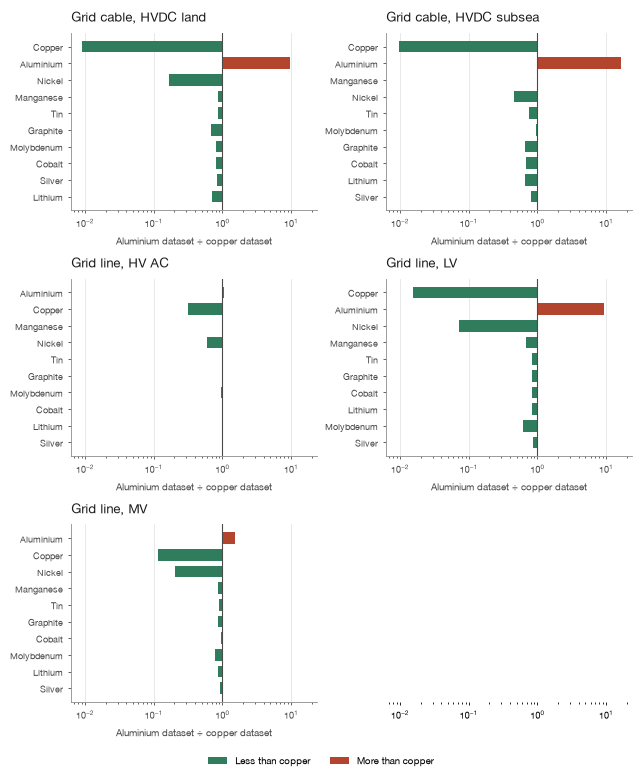

In [10]:
RELIEF, LOAD = "#2f7d5c", "#b3452f"  # less of the mineral than copper / more of it
MOVE_NAMES = {RELIEF: "Less than copper", LOAD: "More than copper"}


def pair_ratios(copper_label, n=PAIR_MINERALS):
    """Same rows as the levels panel, as multiples of the copper parent."""
    p = pairs[
        (pairs[ConductorComparison.copper_sub_technology] == copper_label)
        & pairs[ConductorComparison.ratio].notna()  # copper parent embodies none of it
    ]
    return p.head(n).iloc[::-1]


# One x-scale across the panels: the point of this view is which grid the swap moves
# most, which a per-panel scale would flatten (HV AC bottoms out at 0.33, the HVDC
# cables at 0.02, and free scales would draw both the same length).
fig, axes = plotting.page_grid(
    len(copper_labels),
    style,
    max_columns=PAIR_COLUMNS,
    row_height=plotting.bar_panel_height(PAIR_MINERALS, style),
    sharex=True,
)
for ax, copper_label in zip(axes, copper_labels):
    p = pair_ratios(copper_label)
    ratio = p[ConductorComparison.ratio]
    # Bars span between 1 and the ratio, so they diverge about the no-change line
    # rather than all growing from the left edge of the log axis.
    ax.barh(
        p[ConductorComparison.mineral],
        ratio - 1,
        left=1,
        color=np.where(ratio < 1, RELIEF, LOAD),
        height=0.7,
    )
    ax.axvline(1, color=ink["secondary"], linewidth=0.8)  # unchanged by the swap
    plotting.style_panel(
        ax, style, title=copper_label, log=True, orientation="horizontal",
        ylabel="Aluminium dataset ÷ copper dataset",
    )
    # sharex leaves ticks on the bottom row only, and this grid has a hole in it.
    ax.tick_params(axis="x", labelbottom=True)

legend = fig.legend(
    handles=plotting.patch_handles(
        (RELIEF, LOAD), {key: key for key in (RELIEF, LOAD)}, MOVE_NAMES
    ),
    loc="outside lower center", frameon=False, ncol=2,
)
plotting.save_figure(
    fig, figures_dir, "conductor_substitution_ratio", style, (legend,)
)